In [3]:
# install.packages("devtools")
devtools::install_github("r-lib/conflicted")

Skipping install of 'conflicted' from a github remote, the SHA1 (4d759ac6) has not changed since last install.
  Use `force = TRUE` to force installation



In [4]:
dplyr::filter(mtcars, am & cyl == 8)
#>                 mpg cyl disp  hp drat   wt qsec vs am gear carb
#> Ford Pantera L 15.8   8  351 264 4.22 3.17 14.5  0  1    5    4
#> Maserati Bora  15.0   8  301 335 3.54 3.57 14.6  0  1    5    8

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Ford Pantera L,15.8,8,351,264,4.22,3.17,14.5,0,1,5,4
Maserati Bora,15.0,8,301,335,3.54,3.57,14.6,0,1,5,8


In [5]:
# 2. Cargando la base de datos metereorológicos

ruta_archivo <- if (file.exists("datos/cibmeteo.csv")) {"datos/cibmeteo.csv"} else if (file.exists("cibmeteo.csv")) 
{"cibmeteo.csv"} else if (file.exists("datos/cibmeteo.txt")) 
{"datos/cibmeteo.txt"} else {"cibmeteo.txt"}


In [6]:
# 3 Lectura de los datos generados para contabilizar los registros 
if (grepl("\\.csv$", ruta_archivo)) {datos_meteo <- read.csv(ruta_archivo, stringsAsFactors = FALSE)} else {datos_meteo <- read.delim(ruta_archivo, header = TRUE, sep = "\t", stringsAsFactors = FALSE)}
cat("Datos cargados exitosamente. Total de registros:", nrow(datos_meteo), "\n\n")

Datos cargados exitosamente. Total de registros: 17364 



In [7]:
### Definición y documentación de la función propia en R ##

In [8]:
# Analizando los eventos de viento
#
# @description: Filtra el dataset meteorológico por un rango de velocidad del viento (m/s) y calcula métricas descriptivas clave de temperatura y humedad asociada.
# @param df: Data frame con las variables 'wind_spd', 'temperature' y 'rel_hum'.
# @param viento_min: Límite inferior de velocidad del viento en m/s (por defecto: 0).
# @param viento_max: Límite superior de velocidad del viento en m/s (por defecto: 10).
# @return: Regresando una lista con dos elementos $estadisticas (resumen) y $datos_filtrados (subconjunto).

In [9]:
analizar_eventos_viento <- function(df, viento_min = 0, viento_max = 10) {
  
  # Validación de seguridad: verificar que las columnas necesarias existan
  cols_requeridas <- c("wind_spd", "temperature", "rel_hum")
  if (!all(cols_requeridas %in% colnames(df))) {stop("Error: El data frame no contiene las columnas requeridas (wind_spd, temperature, rel_hum).")}
  
  # Filtrado de datos dentro del rango térmico / eólico especificado
  subconjunto <- df %>%
    filter(wind_spd >= viento_min & wind_spd <= viento_max)
  
  # Cálculo de indicadores estadísticos clave
  resumen_estadistico <- subconjunto %>%
    summarise(
      n_registros      = n(),
      viento_promedio  = round(mean(wind_spd, na.rm = TRUE), 2),
      viento_maximo    = round(max(wind_spd, na.rm = TRUE), 2),
      temp_promedio    = round(mean(temperature, na.rm = TRUE), 2),
      humedad_promedio = round(mean(rel_hum, na.rm = TRUE), 2))
  
  # Retorno estructurado como objeto de lista
  return(list(estadisticas = resumen_estadistico,datos_filtrados = subconjunto))}

In [10]:
## Prueba de ejecución de la función personalizada 
cat("--- DEMOSTRACIÓN DE LA FUNCIÓN: Eventos de Viento Moderado (> 3 m/s) ---\n") 
resultado_viento <- analizar_eventos_viento(datos_meteo, viento_min = 3, viento_max = 8) 
print(resultado_viento$estadisticas)


--- DEMOSTRACIÓN DE LA FUNCIÓN: Eventos de Viento Moderado (> 3 m/s) ---
  n_registros viento_promedio viento_maximo temp_promedio humedad_promedio
1         117            3.41          6.53         23.16            61.78


In [11]:
### Durante la preparación de los datos para poder visualizarlos, es necesario extraer la hora numérica (0 a 23) eliminando los minutos tras los dos puntos (":")
datos_meteo <- datos_meteo %>% mutate(hora_int = as.numeric(sub(":.*", "", hour)))

In [12]:
# Calculando la temperatura promedio por hora para el mapeo continuo de calor
resumen_horario <- datos_meteo %>% group_by(hora_int) %>% summarise(temp_promedio_hora = mean(temperature, na.rm = TRUE))

In [13]:
# Añadiendo el promedio calculado al dataset principal mediante la función "left_join"
datos_meteo_plot <- datos_meteo %>%
  left_join(resumen_horario, by = "hora_int")

In [14]:
### Elaboración del gráfico de distribución por horas de la temperatura
grafico_temperatura_hora <- ggplot(
  data = datos_meteo_plot, 
  aes(x = factor(hora_int), y = temperature, fill = temp_promedio_hora)) +
  geom_boxplot(alpha = 0.8, outlier.size = 0.6, outlier.color = "grey40") +
  scale_fill_gradient(
    low = "#2b5c8f", 
    high = "#d95f02", 
    name = "Temp. Media (°C)") +
  theme_minimal(base_size = 12) +
  labs(title = "Variación Diurna de la Temperatura Costera",
    subtitle = "Distribución horaria basada en 17,364 mediciones (2006-2007)",
    x = "Hora del Día (00:00 - 23:00 hrs)",
    y = "Temperatura (°C)") +
  theme(plot.title = element_text(face = "bold", size = 14),panel.grid.minor = element_blank(),
    axis.text.x = element_text(angle = 0, hjust = 0.5))


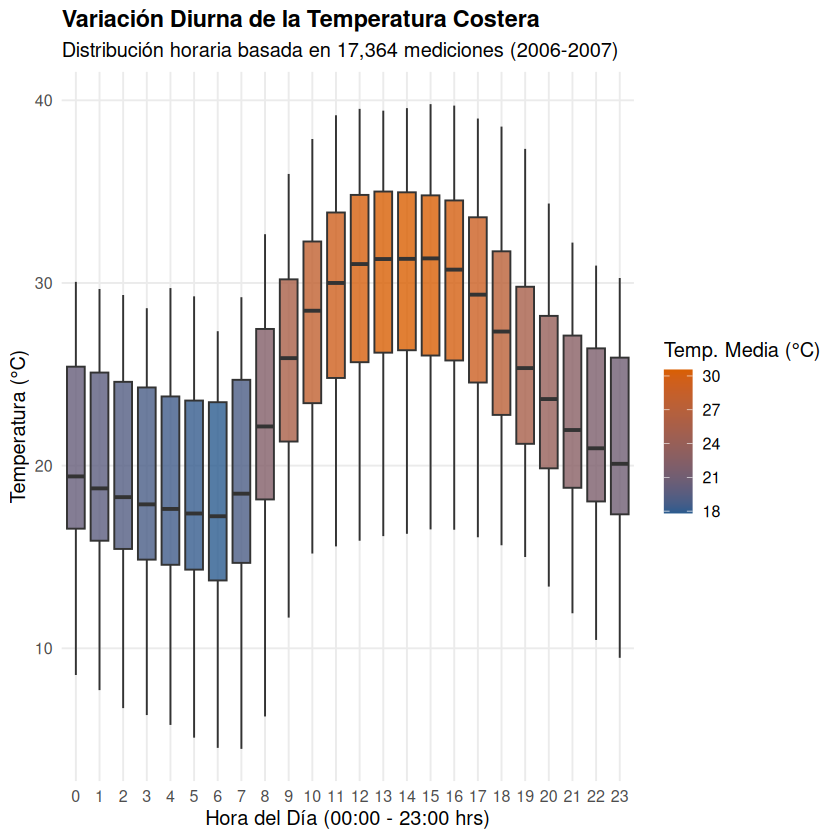

In [15]:
# Renderizar Gráfico 1 en el cuaderno
print(grafico_temperatura_hora)

In [16]:
## Gráfico 2. Regresión líneal entre humedad relativa y la temperatura
grafico_humedad_temp <- ggplot(data = datos_meteo, aes(x = rel_hum, y = temperature)) +
  geom_point(alpha = 0.15, color = "#2c7fb8", size = 1) +
  geom_smooth(method = "lm", color = "#e31a1c", linewidth = 1.2, se = TRUE) +
  theme_minimal(base_size = 12) +
  labs(title = "Relación de Dependencia entre Humedad Relativa y Temperatura",
    subtitle = "Ajuste mediante Regresión Lineal Simple (método 'lm')",
    x = "Humedad Relativa (%)",
    y = "Temperatura (°C)") +
  theme(plot.title = element_text(face = "bold", size = 14))


`geom_smooth()` using formula = 'y ~ x'


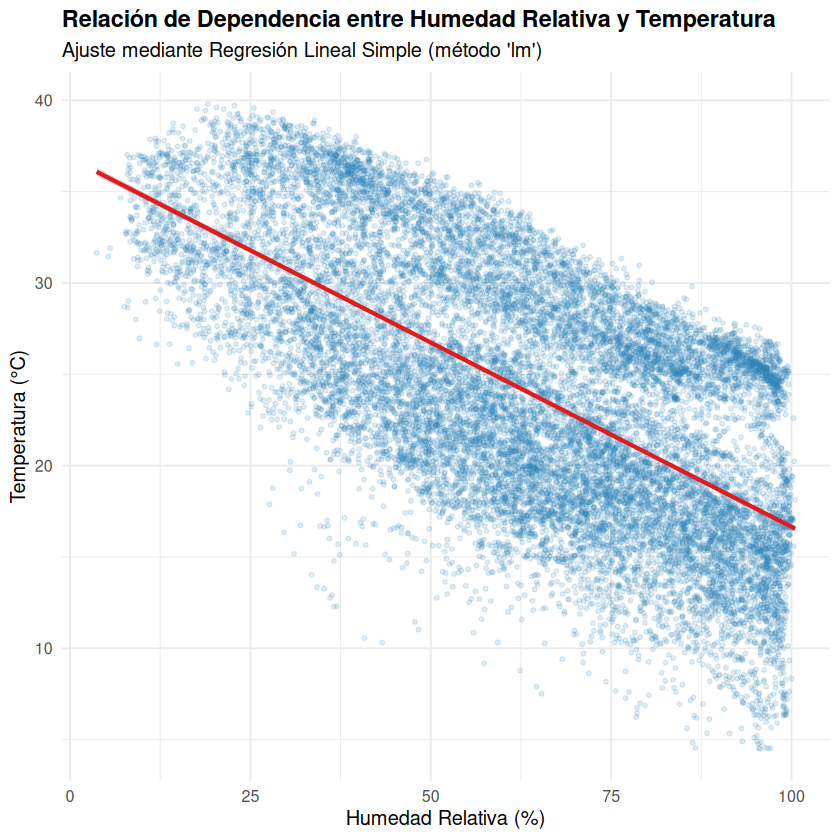

In [17]:
## Imprimiendo el gráfico en el cuaderno
print(grafico_humedad_temp)